In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

parametros 

In [2]:
m = 20.0  # Masa [kg]
k = 20.0  # Constante del resorte [N/m]

x0 = 1.0  # Desplazamiento inicial [m]
v0 = 0.0  # Velocidad inicial [m/s]
cond_iniciales = [x0, v0]


In [3]:
t_span = (0.0, 15.0) # Intervalo de tiempo
t_eval = np.linspace(0.0, 15.0, 600)

CASOSO DE AMOTIGUAMIENTO

In [4]:
casos = [
    {"c": 5.0, "label": "c = 5 N·s/m (Subamortiguado)", "color": "blue"},
    {"c": 40.0, "label": "c = 40 N·s/m (Crítico)", "color": "green"},
    {"c": 200.0, "label": "c = 200 N·s/m (Sobreamortiguado)", "color": "red"},
]


SISTEMA DE ECUACIONES


In [5]:
def sistema_masa_resorte(t, y, m, c, k):
    x, v = y
    dxdt = v
    dvdt = (-c * v - k * x) / m
    return [dxdt, dvdt]

integracion 

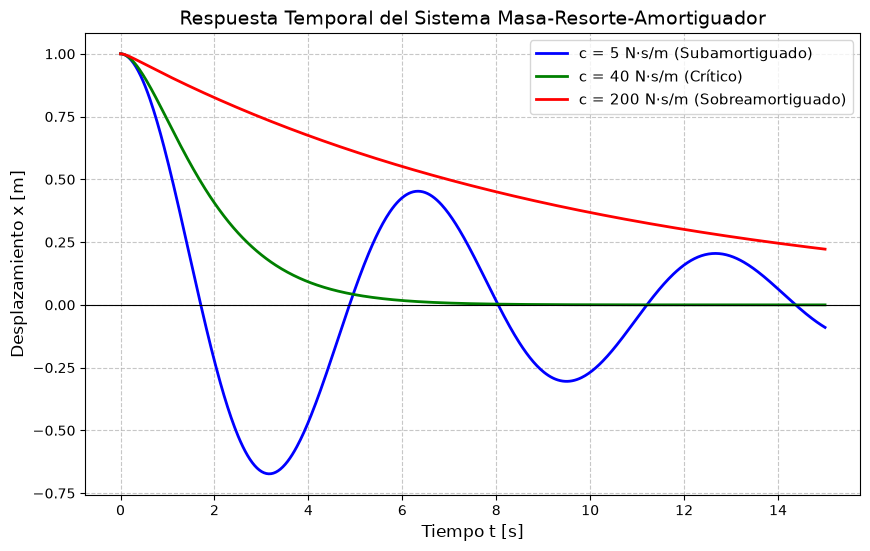

In [9]:
plt.figure(figsize=(10, 6))

for caso in casos:
    c = caso["c"]
    sol = solve_ivp(
        sistema_masa_resorte,
        t_span,
        cond_iniciales,
        args=(m, c, k),
        t_eval=t_eval,
        method="RK45",
    )

    plt.plot(
        sol.t,
        sol.y[0],
        label=caso["label"],
        color=caso["color"],
        linewidth=2.0,
    )
    plt.title(
    "Respuesta Temporal del Sistema Masa-Resorte-Amortiguador", fontsize=14
)
plt.xlabel("Tiempo t [s]", fontsize=12)
plt.ylabel("Desplazamiento x [m]", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(fontsize=11)
plt.axhline(0, color="black", linestyle="-", linewidth=0.8)

CURVA AZUL: La masa oscila alrededor del punto de equilibrio ($x = 0$), cruzando el eje horizontal varias veces.  

CURVA VERDE:Es el caso límite donde la masa regresa lo más rápido posible al punto de equilibrio ($x = 0$) en aproximadamente 7 segundos sin oscilar ni cruzarse hacia valores negativos. 

CURVA ROJA: Hay tanta resistencia en el amortiguador que el movimiento es muy lento.